# 05 · Marcos da temporada: previsão de início, pico e fim

Em cada origem $o$ da temporada (SE 1 a 35 de 2024, 2025 e 2026), a trajetória da temporada é o observado na versão da origem (nowcast) até a última semana usada, completado por amostras do modelo até o fim da temporada. Os marcos de cada amostra seguem a definição *a priori* (`vsr_comum.marcos_amostras`: início/fim = fração acumulada 0,10/0,90; pico = argmax da média móvel centrada de 3 semanas), a mesma da verdade em `eda_marcos_temporada.parquet`. Código em `vsr_modelos.py`; método em `docs/METODOLOGIA.md` §12.

- **Modelos:** `naive_sazonal`, `climatologia` (baseline do *timing*), `nb_local`, `arima_fourier` (região e Brasil), `forma_curva` (molde das temporadas anteriores deslocado e esticado, §12.5) `ensemble` (mistura das amostras) e `ensemble_pond` (mistura com pesos ∝ 1/RPS das temporadas anteriores; `vm.ensemble_ponderado`). LightGBM e ETS não geram uma temporada inteira.
- **Nowcast:** as semanas $o - 26 \dots o - 1$ de cada trajetória vêm de uma amostra do nowcast `gamma_rw` (§6.1); o NB parte da mesma amostra.
- **Métricas:** RPS (CRPS discreto, em semanas), erro absoluto da mediana, $P(|\text{erro}| \le 1)$ e cobertura de 80%, por antecedência = semana real − semana da origem.
- **2026:** verdade provisória (temporada em curso); o fim de 2026 não é avaliado.
- **Saídas:** `previsoes_marcos.parquet` (distribuição em 53 semanas) e `avaliacao_marcos.parquet`.

In [1]:
import logging
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

import vsr_modelos as vm
from vsr_comum import P, verificar_ambiente

verificar_ambiente()
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s", stream=sys.stdout, force=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

TIERS = pd.read_csv(P / "tiers_uf.csv").set_index("unidade")["tier"]
VER = (pd.read_parquet(P / "eda_marcos_temporada.parquet").query("serie == @vm.SERIE")
       .melt(id_vars=["nivel", "unidade", "temporada", "completa"], value_vars=list(vm.MARCOS),
             var_name="marco", value_name="semana_real").dropna(subset=["semana_real"]))
VER = VER.loc[VER["completa"] | (VER["marco"] != "fim")].drop(columns="completa")   # fim de 2026 não avaliado
ORIGENS = [o for o in pd.date_range("2023-12-31", "2026-08-09", freq="7D")
           if (o - vm.domingo_se1((o + pd.Timedelta(days=3)).year)).days // 7 + 1 <= 35]
print(f"{len(ORIGENS)} origens: {ORIGENS[0].date()} a {ORIGENS[-1].date()}")

102 origens: 2023-12-31 a 2026-08-09


## 1. Backtest das trajetórias

In [2]:
t0 = time.time()
PREV = vm.backtest_marcos(ORIGENS)
PREV = pd.concat([PREV, vm.ensemble_ponderado(PREV, vm.pontuar_marcos(PREV, VER))], ignore_index=True)
PREV.to_parquet(P / f"previsoes_marcos{vm.sufixo()}.parquet", index=False)
SC = vm.pontuar_marcos(PREV, VER)
SC["grupo"] = np.where(SC["nivel"] == "UF", "UF " + SC["unidade"].map(TIERS), np.where(SC["nivel"] == "BRASIL", "BR", "REGIAO"))
SC["faixa_antec"] = pd.cut(SC["antecedencia"], [-60, 0, 2, 4, 8, 60], labels=["≤ 0", "1–2", "3–4", "5–8", "≥ 9"])
SC.to_parquet(P / f"avaliacao_marcos{vm.sufixo()}.parquet", index=False)
print(f"{len(PREV):,} distribuições em {time.time() - t0:.0f} s; {len(SC):,} avaliadas")

2026-10-20 01:29:32,260 INFO marcos: origem 2023-12-31 (1/102)


2026-10-20 01:29:49,699 INFO marcos: origem 2024-03-10 (11/102)


2026-10-20 01:30:07,404 INFO marcos: origem 2024-05-19 (21/102)


2026-10-20 01:30:25,855 INFO marcos: origem 2024-07-28 (31/102)


2026-10-20 01:30:43,881 INFO marcos: origem 2025-02-02 (41/102)


...

2026-10-20 01:31:38,390 INFO marcos: origem 2026-01-04 (71/102)


2026-10-20 01:31:57,570 INFO marcos: origem 2026-03-15 (81/102)


2026-10-20 01:32:15,386 INFO marcos: origem 2026-05-24 (91/102)


2026-10-20 01:32:33,420 INFO marcos: origem 2026-08-02 (101/102)


62,424 distribuições em 185 s; 55,896 avaliadas


## 2. Acurácia por antecedência

Média sobre origens, unidades e temporadas. Antecedência ≤ 0: o evento já ocorreu (ou ocorre na semana da origem) e é estimado com dados parciais. Os grupos BR e REGIAO e as UFs do tier A são o recorte principal; nos tiers B e C, o início e o pico são avaliados na região (regra *a priori*).

In [3]:
PRINC = SC.loc[SC["grupo"].isin(["BR", "REGIAO", "UF A"])]
for met in ("rps", "ea_mediana", "p_1sem"):
    print(met)
    display(PRINC.pivot_table(index=["marco", "modelo"], columns="faixa_antec", values=met, observed=True)
            .round(2))

rps


faixa_antec            ≤ 0   1–2   3–4   5–8   ≥ 9
marco  modelo                                     
fim    arima_fourier  4.16  4.21  3.77  4.12  6.34
       climatologia   1.92  3.28  3.92  4.53  6.51
       ensemble       2.10  2.74  2.94  3.41  4.91
       ensemble_pond  2.14  2.79  3.00  3.48  5.07
       forma_curva    3.65  4.24  4.19  4.29  5.54
       naive_sazonal  2.99  3.31  3.47  3.61  3.79
       nb_local       2.15  2.99  3.08  3.64  6.11
inicio arima_fourier  0.48  1.10  1.16  1.12  1.62
       climatologia   0.65  1.37  1.46  1.99  3.14
       ensemble       0.55  1.23  1.30  1.59  2.53
       ensemble_pond  0.56  1.22  1.30  1.60  2.54
       forma_curva    0.72  2.09  1.78  1.69  2.41
       naive_sazonal  1.07  1.25  1.44  1.91  2.60
       nb_local       0.71  1.67  1.62  1.74  2.82
pico   arima_fourier  0.27  1.23  1.39  1.61  1.55
       climatologia   0.88  2.58  2.76  2.48  2.90
       ensemble       0.56  1.66  1.80  1.87  2.33
       ensemble_pond  0.60  1.64  1.78  1.86  2.32
       forma_curva    0.39  2.10  2.37  2.39  2.32
       naive_sazonal  1.64  1.61  1.71  1.85  2.57
       nb_local       0.47  1.86  2.13  2.26  2.47

ea_mediana


faixa_antec            ≤ 0   1–2   3–4   5–8   ≥ 9
marco  modelo                                     
fim    arima_fourier  5.37  5.64  5.00  5.46  8.33
       climatologia   2.70  4.50  5.07  6.04  8.21
       ensemble       2.83  3.73  3.93  4.49  6.27
       ensemble_pond  2.87  3.86  3.99  4.63  6.50
       forma_curva    4.46  5.05  5.00  5.31  6.79
       naive_sazonal  3.66  4.10  4.28  4.48  4.91
       nb_local       2.80  3.90  3.90  4.58  7.78
inicio arima_fourier  0.67  1.50  1.69  1.61  2.22
       climatologia   0.82  1.80  1.94  2.65  4.04
       ensemble       0.74  1.69  1.83  2.19  3.33
       ensemble_pond  0.76  1.73  1.90  2.23  3.33
       forma_curva    0.86  2.48  2.06  2.13  3.15
       naive_sazonal  1.30  1.59  1.88  2.46  3.19
       nb_local       0.90  2.21  2.18  2.36  3.46
pico   arima_fourier  0.36  1.78  2.08  2.18  2.22
       climatologia   0.79  3.55  3.85  3.34  3.84
       ensemble       0.70  2.39  2.55  2.53  3.17
       ensemble_pond  0.73  2.43  2.57  2.54  3.16
       forma_curva    0.51  2.73  3.04  3.08  3.06
       naive_sazonal  2.00  2.20  2.42  2.74  3.59
       nb_local       0.64  2.57  2.92  2.97  3.28

p_1sem


faixa_antec            ≤ 0   1–2   3–4   5–8   ≥ 9
marco  modelo                                     
fim    arima_fourier  0.36  0.23  0.21  0.19  0.14
       climatologia   0.61  0.15  0.15  0.17  0.15
       ensemble       0.51  0.25  0.23  0.22  0.18
       ensemble_pond  0.51  0.25  0.23  0.22  0.17
       forma_curva    0.46  0.28  0.27  0.25  0.19
       naive_sazonal  0.40  0.22  0.21  0.23  0.23
       nb_local       0.59  0.35  0.30  0.24  0.16
inicio arima_fourier  0.85  0.47  0.44  0.44  0.31
       climatologia   0.79  0.42  0.33  0.24  0.15
       ensemble       0.80  0.45  0.39  0.32  0.20
       ensemble_pond  0.80  0.45  0.39  0.32  0.20
       forma_curva    0.81  0.30  0.36  0.34  0.22
       naive_sazonal  0.76  0.65  0.45  0.34  0.23
       nb_local       0.84  0.41  0.39  0.34  0.18
pico   arima_fourier  0.87  0.35  0.32  0.31  0.30
       climatologia   0.79  0.16  0.21  0.22  0.18
       ensemble       0.81  0.27  0.27  0.26  0.23
       ensemble_pond  0.80  0.28  0.27  0.26  0.23
       forma_curva    0.85  0.23  0.25  0.28  0.25
       naive_sazonal  0.72  0.39  0.32  0.26  0.21
       nb_local       0.85  0.31  0.29  0.29  0.25

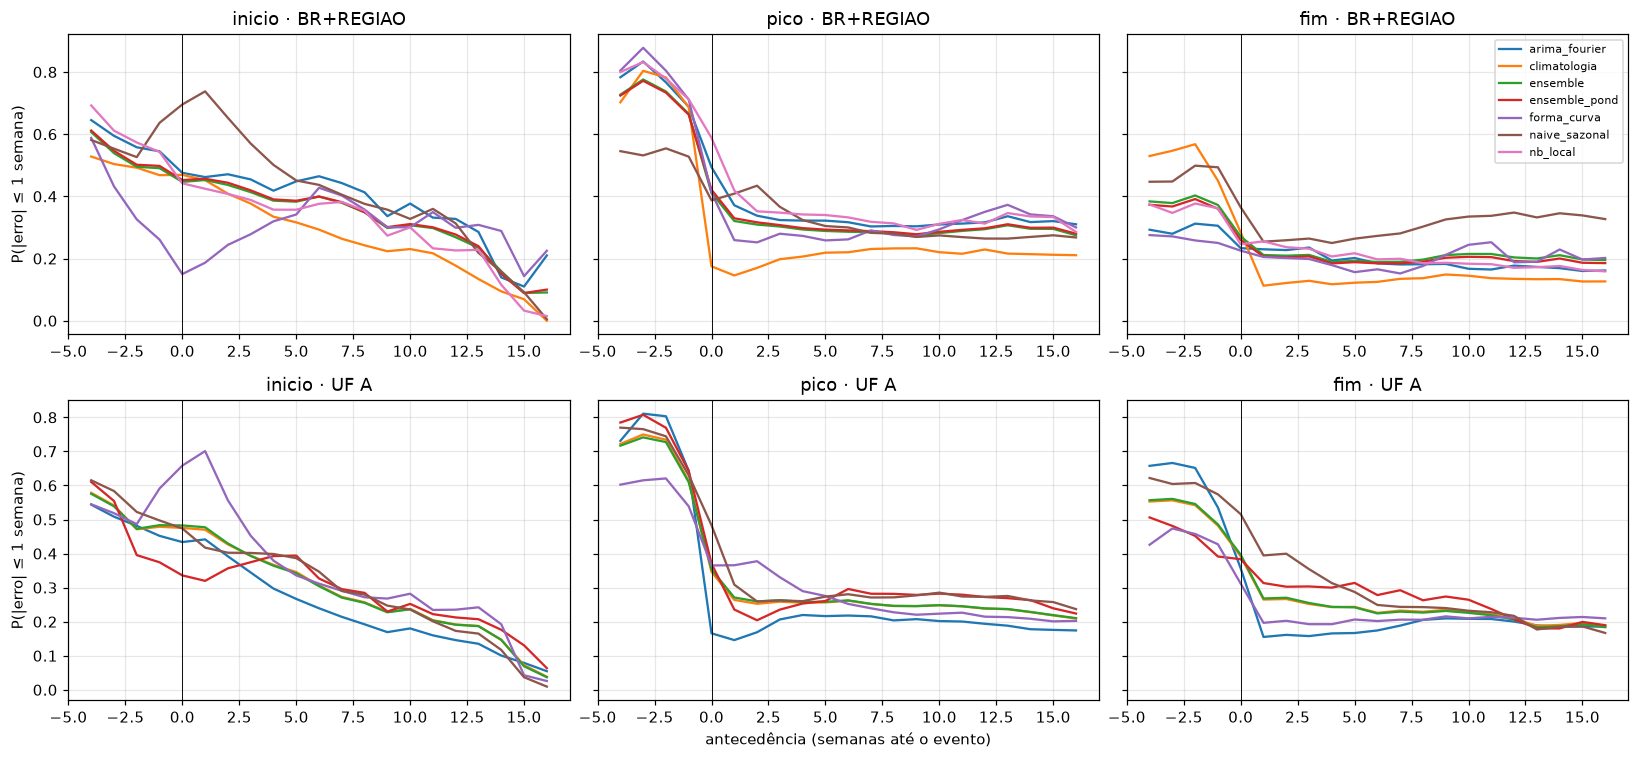

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for j, mc in enumerate(vm.MARCOS):
    for i, grp in enumerate((["BR", "REGIAO"], ["UF A"])):
        ax = axs[i, j]
        d = SC.loc[(SC["marco"] == mc) & SC["grupo"].isin(grp) & SC["antecedencia"].between(-4, 16)]
        for m, g in d.groupby("modelo"):
            ax.plot(*g.groupby("antecedencia")["p_1sem"].mean().pipe(lambda s: (s.index, s.values)), label=m)
        ax.set_title(f"{mc} · {'+'.join(grp)}"); ax.axvline(0, color="k", lw=0.6)
axs[1, 1].set_xlabel("antecedência (semanas até o evento)"); axs[0, 0].set_ylabel("P(|erro| ≤ 1 semana)")
axs[1, 0].set_ylabel("P(|erro| ≤ 1 semana)"); axs[0, -1].legend(fontsize=7); fig.tight_layout()

## 3. Calibração: cobertura do intervalo de 80% (antecedência ≥ 1)

In [5]:
fut = SC.loc[SC["antecedencia"] >= 1]
display(fut.pivot_table(index=["marco", "modelo"], columns="grupo", values="cob80").round(2))

grupo                   BR  REGIAO  UF A  UF B  UF C
marco  modelo                                       
fim    arima_fourier  0.46    0.49   NaN   NaN   NaN
       climatologia   0.35    0.46  0.49  0.41  0.42
       ensemble       0.51    0.49  0.58  0.56  0.93
       ensemble_pond  0.51    0.49  0.58  0.55  0.92
       forma_curva    0.37    0.34  0.41  0.38  0.70
       naive_sazonal  0.37    0.56  0.37  0.48  0.68
       nb_local       0.39    0.37  0.46  0.43  0.52
inicio arima_fourier  0.68    0.61   NaN   NaN   NaN
       climatologia   0.62    0.49  0.42  0.54  0.46
       ensemble       0.68    0.66  0.56  0.65  0.71
       ensemble_pond  0.68    0.65  0.56  0.65  0.70
       forma_curva    0.47    0.50  0.50  0.50  0.44
       naive_sazonal  0.71    0.51  0.43  0.42  0.55
       nb_local       0.65    0.44  0.43  0.61  0.59
pico   arima_fourier  0.96    0.76   NaN   NaN   NaN
       climatologia   0.98    0.94  0.71  0.60  0.64
       ensemble       1.00    0.82  0.71  0.75  0.80
       ensemble_pond  1.00    0.82  0.71  0.75  0.80
       forma_curva    0.55    0.59  0.54  0.61  0.64
       naive_sazonal  1.00    0.87  0.65  0.49  0.58
       nb_local       0.64    0.65  0.62  0.70  0.73

## 4. Teste de sinal pareado contra os baselines

Por par unidade-temporada, RPS médio nas origens com antecedência de 1 a 8 semanas (decisão acionável). Vitória = RPS do modelo < RPS do baseline; teste binomial bilateral com p = 0,5 (empates descartados). Recorte principal: BR, regiões e UFs do tier A. Dois baselines: `climatologia` (amostra cada semana de forma independente e, fora da temporada, gera picos espúrios tardios, sendo fraca para *timing*) e `naive_sazonal` (formato da temporada anterior).

In [6]:
acao = PRINC.loc[PRINC["antecedencia"].between(1, 8)]
par = acao.pivot_table(index=["marco", "unidade", "temporada"], columns="modelo", values="rps")
linhas = []
for base in ("climatologia", "naive_sazonal"):
    for mc, d in par.groupby(level="marco"):
        for m in [c for c in d.columns if c not in ("climatologia", "naive_sazonal")]:
            x = d[[m, base]].dropna()
            dif = x[m] - x[base]
            v, n = int((dif < 0).sum()), int((dif != 0).sum())
            linhas.append({"baseline": base, "marco": mc, "modelo": m, "vitorias": v, "pares": n,
                           "p_valor": binomtest(v, n, 0.5).pvalue if n else np.nan,
                           "rps_modelo": x[m].mean(), "rps_base": x[base].mean()})
SINAL = pd.DataFrame(linhas)
display(SINAL.round(3))

,baseline,marco,modelo,vitorias,pares,p_valor,rps_modelo,rps_base
0,climatologia,fim,arima_fourier,10,12,0.039,4.092,4.888
1,climatologia,fim,ensemble,34,41,0.000,3.165,4.126
2,climatologia,fim,ensemble_pond,34,41,0.000,3.229,4.126
3,climatologia,fim,forma_curva,23,41,0.533,4.262,4.126
4,climatologia,fim,nb_local,35,41,0.000,3.390,4.126
5,climatologia,inicio,arima_fourier,15,18,0.008,1.169,1.532
6,climatologia,inicio,ensemble,45,63,0.001,1.504,1.772
7,climatologia,inicio,ensemble_pond,45,63,0.001,1.513,1.772
8,climatologia,inicio,forma_curva,30,63,0.801,1.881,1.772
9,climatologia,inicio,nb_local,39,63,0.077,1.730,1.772


## 5. Exemplo: distribuição prevista do pico ao longo da temporada

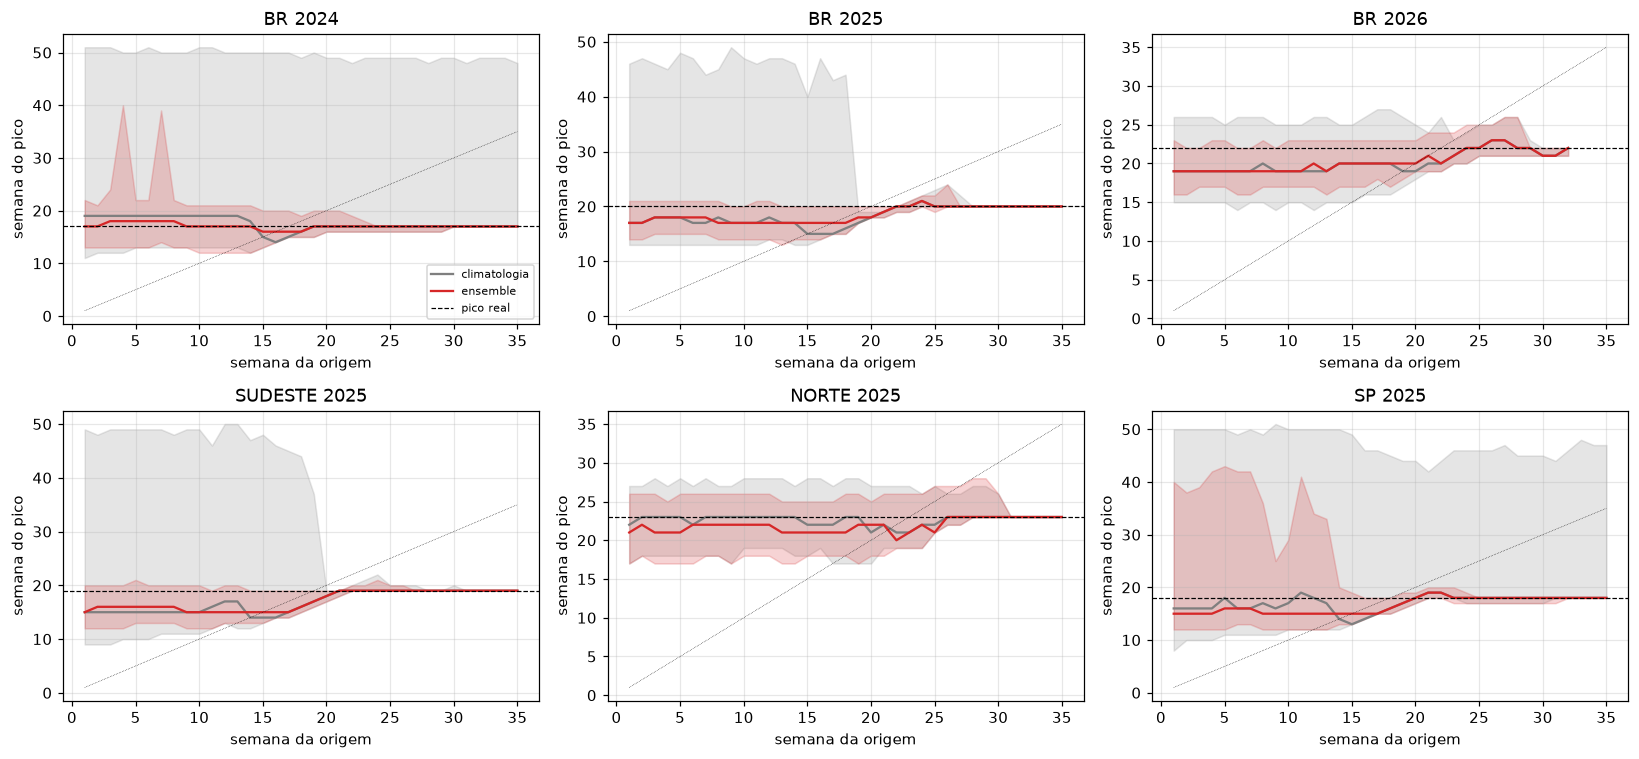

In [7]:
EX = [("BR", 2024), ("BR", 2025), ("BR", 2026), ("SUDESTE", 2025), ("NORTE", 2025), ("SP", 2025)]
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, (u, t) in zip(axs.flat, EX):
    for m, cor in (("climatologia", "tab:gray"), ("ensemble", "tab:red")):
        d = SC.loc[(SC["unidade"] == u) & (SC["temporada"] == t) & (SC["marco"] == "pico") & (SC["modelo"] == m)]
        p = PREV.loc[(PREV["unidade"] == u) & (PREV["temporada"] == t) & (PREV["marco"] == "pico")
                     & (PREV["modelo"] == m)].sort_values("semana_origem")
        F = np.cumsum(p[vm.COLS_P].to_numpy(), 1)
        q = lambda a: (F >= a).argmax(1) + 1  # noqa: E731
        ax.fill_between(p["semana_origem"], q(0.1), q(0.9), color=cor, alpha=0.2)
        ax.plot(p["semana_origem"], q(0.5), color=cor, label=m)
    real = VER.query("unidade == @u and temporada == @t and marco == 'pico'")["semana_real"]
    if len(real):
        ax.axhline(real.iloc[0], color="k", ls="--", lw=0.8, label="pico real")
    ax.plot([1, 35], [1, 35], color="k", lw=0.4, ls=":")
    ax.set_title(f"{u} {t}"); ax.set_xlabel("semana da origem"); ax.set_ylabel("semana do pico")
axs[0, 0].legend(fontsize=7); fig.tight_layout()

## 5b. Sensibilidade à definição de início e fim

As distribuições previstas (definição *a priori*) pontuadas contra as verdades alternativas de `02_eda` §7b (MEM e limiar de taxa). Não há nova previsão: mede se as conclusões sobre os modelos dependem da definição usada na verdade. Teste de sinal contra o `naive_sazonal`, antecedência 1–8 semanas, BR + regiões + UF A.

In [8]:
E = pd.read_parquet(P / "eda_marcos_temporada.parquet").query("serie == @vm.SERIE")
linhas = []
for alt in (("mem", "taxa") if vm.SERIE == "vsr" else ()):   # definições alternativas só para o vsr
    va = (E.rename(columns={"inicio_" + alt: "inicio_alt", "fim_" + alt: "fim_alt"})
          .melt(id_vars=["nivel", "unidade", "temporada", "completa"], value_vars=["inicio_alt", "fim_alt"],
                var_name="marco", value_name="semana_real").dropna(subset=["semana_real"]))
    va["marco"] = va["marco"].str.replace("_alt", "")
    va = va.loc[va["completa"] | (va["marco"] != "fim")].drop(columns="completa")
    sa = vm.pontuar_marcos(PREV.loc[PREV["marco"].isin(["inicio", "fim"])], va)
    sa = sa.loc[sa["unidade"].isin(PRINC["unidade"].unique()) & sa["antecedencia"].between(1, 8)]
    par = sa.pivot_table(index=["marco", "unidade", "temporada"], columns="modelo", values="rps")
    for mc, d in par.groupby(level="marco"):
        for m in [c for c in d.columns if c != "naive_sazonal"]:
            x = d[[m, "naive_sazonal"]].dropna()
            dif = x[m] - x["naive_sazonal"]
            v, n = int((dif < 0).sum()), int((dif != 0).sum())
            linhas.append({"definicao": alt, "marco": mc, "modelo": m, "vitorias": v, "pares": n,
                           "p_valor": binomtest(v, n, 0.5).pvalue if n else np.nan,
                           "ea_modelo": sa.loc[(sa["marco"] == mc) & (sa["modelo"] == m), "ea_mediana"].mean()})
SENS = pd.DataFrame(linhas)
display(SENS.round(3))

,definicao,marco,modelo,vitorias,pares,p_valor,ea_modelo
0,mem,fim,arima_fourier,4,10,0.754,5.709
1,mem,fim,climatologia,10,35,0.017,6.993
2,mem,fim,ensemble,17,35,1.000,5.438
3,mem,fim,ensemble_pond,17,35,1.000,5.457
4,mem,fim,forma_curva,16,35,0.736,5.924
5,mem,fim,nb_local,17,35,1.000,5.580
6,mem,inicio,arima_fourier,10,17,0.629,2.535
7,mem,inicio,climatologia,39,60,0.027,2.041
8,mem,inicio,ensemble,38,60,0.052,2.253
9,mem,inicio,ensemble_pond,39,60,0.027,2.240


## 6. Resumo

In [9]:
r = PRINC.loc[PRINC["antecedencia"].between(1, 8)].groupby(["marco", "modelo"])[["rps", "ea_mediana", "p_1sem"]].mean()
print("antecedência 1–8 semanas, BR + regiões + UF A:")
print(r.round(2).to_string())
print("\nteste de sinal (p < 0,05):")
print(SINAL.loc[SINAL["p_valor"] < 0.05, ["baseline", "marco", "modelo", "vitorias", "pares", "p_valor"]]
      .round(4).to_string(index=False))

antecedência 1–8 semanas, BR + regiões + UF A:
                       rps  ea_mediana  p_1sem
marco  modelo                                 
fim    arima_fourier  4.05        5.39    0.20
       climatologia   4.07        5.43    0.16
       ensemble       3.13        4.16    0.23
       ensemble_pond  3.19        4.28    0.23
       forma_curva    4.25        5.17    0.26
       naive_sazonal  3.50        4.34    0.22
       nb_local       3.34        4.24    0.28
inicio arima_fourier  1.13        1.60    0.45
       climatologia   1.70        2.26    0.31
       ensemble       1.43        1.97    0.37
       ensemble_pond  1.43        2.02    0.37
       forma_curva    1.81        2.20    0.34
       naive_sazonal  1.62        2.09    0.44
       nb_local       1.69        2.27    0.37
pico   arima_fourier  1.46        2.06    0.33
       climatologia   2.57        3.52    0.20
       ensemble       1.80        2.50    0.27
       ensemble_pond  1.78        2.52    0.27
       forma_